In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

In [21]:
api = wandb.Api()

username = 'julian-zim-uni-vie'

projects = {
	'll00' : {
		'hgm' : ['hgm-ll0-02-12-01h36-0-2022-11-23_worm10',
				 'hgm-ll0-02-12-16h16-1-2022-11-23_worm11',
				 'hgm-ll0-03-12-06h26-7-2023-11-21_14-46_wt_worm4-2023-11-21',
				 'hgm-ll0-03-12-20h22-11-2023-12-19_17-35_wt_FM_worm4-2023-12-19',
				 'hgm-ll0-04-12-11h04-12-2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
				 'hgm-ll0-05-12-08h57-17-ZIM2165_Gcamp7b_worm1-2022-11-30',
				 'hgm-ll0-01-12-11h07-19-ZIM2165_Gcamp7b_worm1-2022_11_28',
				 'hgm-ll0-05-12-23h59-21-ZIM2165_Gcamp7b_worm2-2022-11-30',],
		'bom' : ['bom-ll0 02.12 08h22 0 2022-11-23_worm10',
				 'bom-ll0 03.12 06h24 1 2022-11-23_worm11',
				 'bom-ll0 04.12 03h09 7 2023-11-21_14-46_wt_worm4-2023-11-21',
				 'bom-ll0 05.12 01h10 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
				 'bom-ll0 05.12 23h09 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
				 'bom-ll0 06.12 21h03 17 ZIM2165_Gcamp7b_worm1-2022-11-30',
				 'bom-ll0 01.12 11h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28',
				 'bom-ll0 07.12 20h51 21 ZIM2165_Gcamp7b_worm2-2022-11-30',],
	},
	'll67' : {
		'hgm' : ['hgm-ll67 02.12 09h08 0 2022-11-23_worm10',
				 'hgm-ll67 03.12 09h17 1 2022-11-23_worm11',
				 'hgm-ll67 04.12 04h25 7 2023-11-21_14-46_wt_worm4-2023-11-21',
				 'hgm-ll67 05.12 00h24 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
				 'hgm-ll67 05.12 16h37 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
				 'hgm-ll67 06.12 12h51 17 ZIM2165_Gcamp7b_worm1-2022-11-30',
				 'hgm-ll67 01.12 11h08 19 ZIM2165_Gcamp7b_worm1-2022_11_28',
				 'hgm-ll67 07.12 12h03 21 ZIM2165_Gcamp7b_worm2-2022-11-30',],
		'bom' : ['bom-ll67 01.12 23h25 0 2022-11-23_worm10',
				 'bom-ll67 02.12 12h58 1 2022-11-23_worm11',
				 'bom-ll67 02.12 23h57 7 2023-11-21_14-46_wt_worm4-2023-11-21',
				 'bom-ll67 03.12 12h25 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
				 'bom-ll67 03.12 23h53 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
				 'bom-ll67 04.12 12h34 17 ZIM2165_Gcamp7b_worm1-2022-11-30',
				 'bom-ll67 01.12 11h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28',
				 'bom-ll67 05.12 02h35 21 ZIM2165_Gcamp7b_worm2-2022-11-30',],
	},
}

hyperparams = {
	'll00' : {
		'hgm' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'w2_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
		'bom' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
	},
	'll67' : {
		'hgm' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'w2_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
		'bom' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
	},
}

In [25]:
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for project in projects[ll][model]:
			if len(project) == 0:
				continue

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')

			print('sorting them...')
			sorted_runs = sorted(runs, key=lambda run: run.summary.get('mpe_loss', float('inf')))
			best_runs = sorted_runs[:int(0.05 * len(sorted_runs))]

			print(f'{model} w1 averaging...')
			best_w1_reg_lambdas = np.array([run.config['w1_reg_lambda'] for run in best_runs])
			hyperparams[ll][model]['w1_reg_lambda']['all'] = best_w1_reg_lambdas
			hyperparams[ll][model]['w1_reg_lambda']['mean']['linear'] = np.mean(best_w1_reg_lambdas)
			hyperparams[ll][model]['w1_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_w1_reg_lambdas)))

			if model == 'hgm':
				print(f'{model} w2 averaging...')
				best_w2_reg_lambdas = np.array([run.config['w2_reg_lambda'] for run in best_runs])
				hyperparams[ll][model]['w2_reg_lambda']['all'] = best_w2_reg_lambdas
				hyperparams[ll][model]['w2_reg_lambda']['mean']['linear'] = np.mean(best_w2_reg_lambdas)
				hyperparams[ll][model]['w2_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_w2_reg_lambdas)))

getting runs for bom-ll0 02.12 08h22 0 2022-11-23_worm10...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 03.12 06h24 1 2022-11-23_worm11...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 04.12 03h09 7 2023-11-21_14-46_wt_worm4-2023-11-21...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 05.12 01h10 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 05.12 23h09 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 06.12 21h03 17 ZIM2165_Gcamp7b_worm1-2022-11-30...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 01.12 11h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28...
sorting them...
bom w1 averaging...
getting runs for bom-ll0 07.12 20h51 21 ZIM2165_Gcamp7b_worm2-2022-11-30...
sorting them...
bom w1 averaging...
getting runs for hgm-ll0-02-12-01h36-0-2022-11-23_worm10...
sorting them...
hgm w1 averaging...
hgm w2 averaging.

In [26]:
with open('./hyperparams.pkl', 'wb') as file:
    pickle.dump(hyperparams, file)

In [2]:
with open('./hyperparams.pkl', 'rb') as file:
    hyperparams = pickle.load(file)

In [3]:
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for param in ['w1_reg_lambda', 'w2_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				print(f'{ll} {model} {param}:\n\t', f'linear: {hyperparams[ll][model][param]['mean']['linear']:.2E}\tgeometric: {hyperparams[ll][model][param]['mean']['geometric']:.2E}')

ll00 bom w1_reg_lambda:
	 linear: 1.20E-02	geometric: 1.20E-02
ll00 hgm w1_reg_lambda:
	 linear: 1.02E-03	geometric: 9.63E-04
ll00 hgm w2_reg_lambda:
	 linear: 1.26E-07	geometric: 4.76E-08
ll67 bom w1_reg_lambda:
	 linear: 5.73E-02	geometric: 5.72E-02
ll67 hgm w1_reg_lambda:
	 linear: 1.03E-02	geometric: 1.01E-02
ll67 hgm w2_reg_lambda:
	 linear: 4.00E-07	geometric: 3.43E-07


In [4]:
hist = False

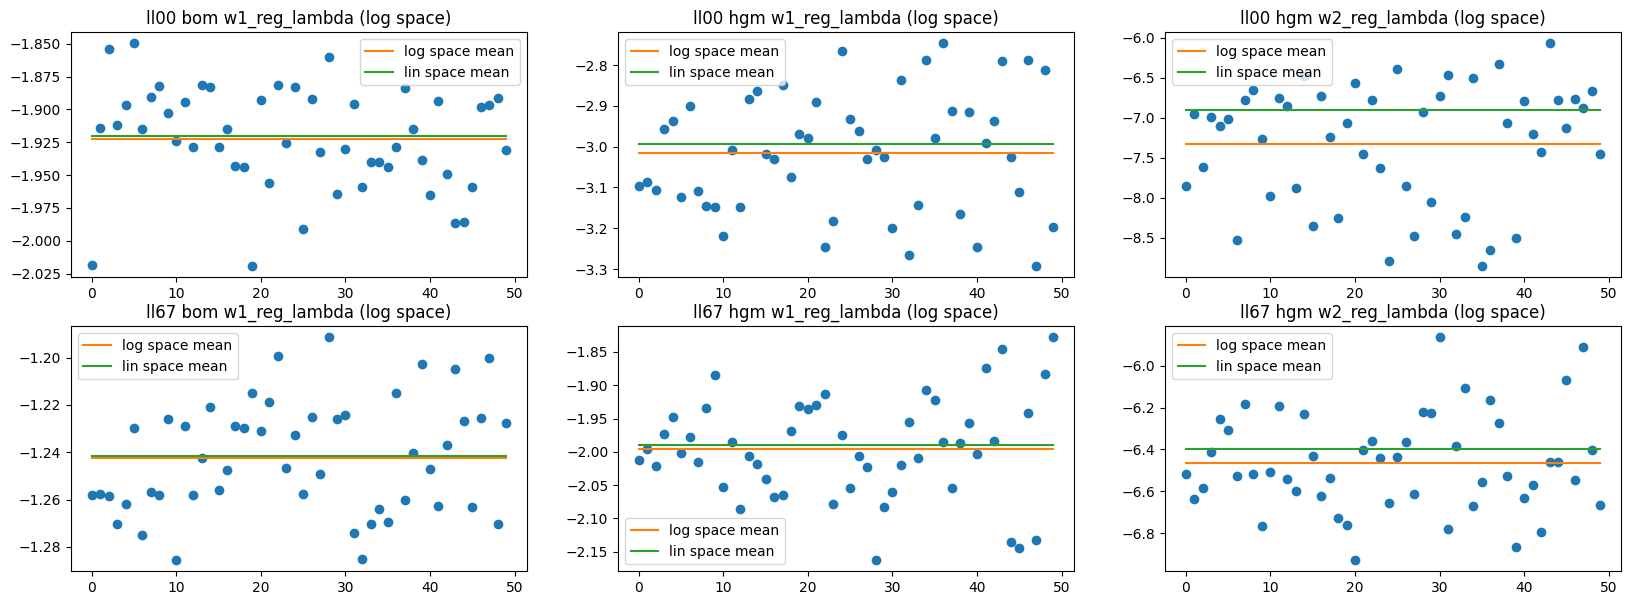

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(20, 7))
idx = 0
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for param in ['w1_reg_lambda', 'w2_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				means = hyperparams[ll][model][param]['mean']
				values = hyperparams[ll][model][param]['all']
				axes[idx // 3, idx % 3].set_title(f'{ll} {model} {param} (log space)')
				if hist:
					axes[idx // 3, idx % 3].hist(np.log10(values), bins=25)
				else:
					axes[idx // 3, idx % 3].plot(np.log10(values), marker='o', linestyle='None')
					axes[idx // 3, idx % 3].plot(np.repeat(np.mean(np.log10(values)), values.shape[0]), label='log space mean')
					axes[idx // 3, idx % 3].plot(np.repeat(np.log10(np.mean(values)), values.shape[0]), label='lin space mean')
					axes[idx // 3, idx % 3].legend()
				idx += 1
			else:
				continue

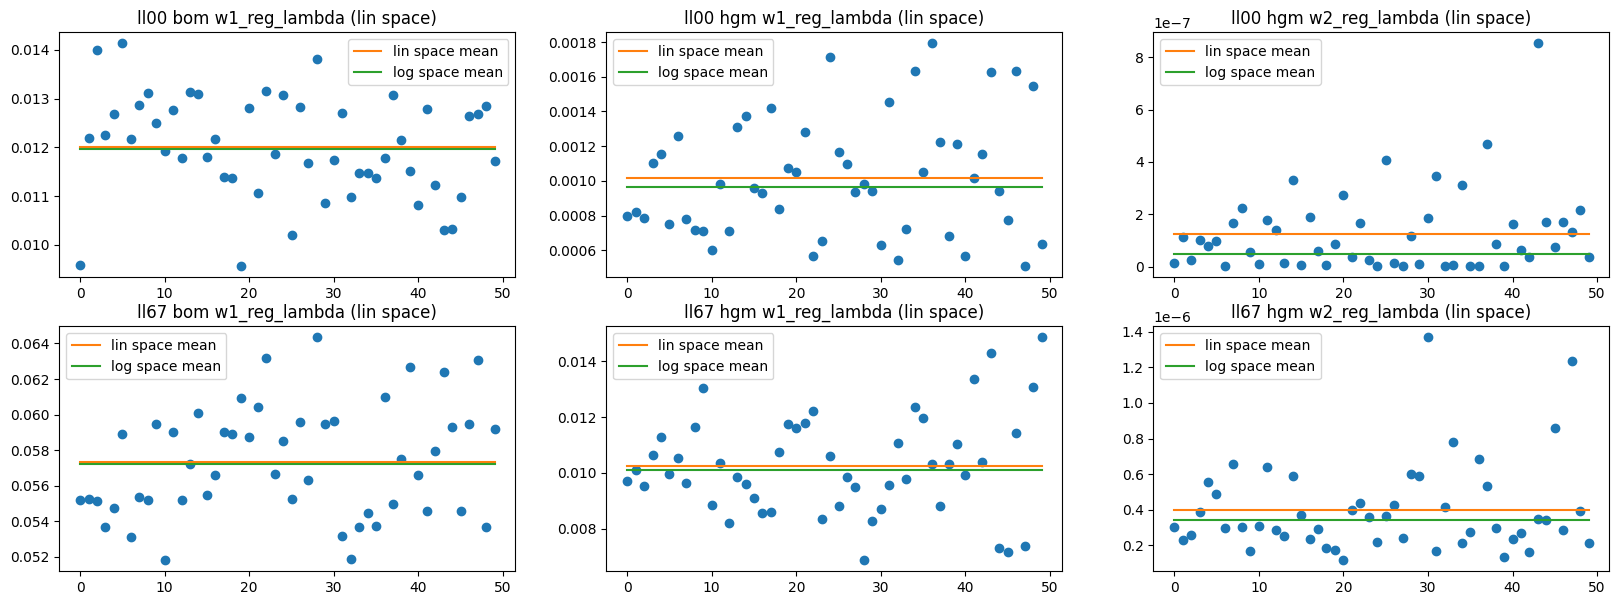

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(20, 7))
idx = 0
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for param in ['w1_reg_lambda', 'w2_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				means = hyperparams[ll][model][param]['mean']
				values = hyperparams[ll][model][param]['all']
				axes[idx // 3, idx % 3].set_title(f'{ll} {model} {param} (lin space)')
				if hist:
					axes[idx // 3, idx % 3].hist(values, bins=25)
				else:
					axes[idx // 3, idx % 3].plot(values, marker='o', linestyle='None')
					axes[idx // 3, idx % 3].plot(np.repeat(means['linear'], values.shape[0]), label='lin space mean')
					axes[idx // 3, idx % 3].plot(np.repeat(means['geometric'], values.shape[0]), label='log space mean')
					axes[idx // 3, idx % 3].legend()
				idx += 1
			else:
				continue